# Operational Perspective and Limitations

Notebooks 01 and 02 treat intrusion detection as a ten-class problem and optimize macro F1. A Security Operations
Centre (SOC) asks two simpler questions first:

1. **Is this flow an attack at all?** (detection rate)
2. **How many alerts will analysts have to look at that turn out to be harmless?** (false positive rate)

This notebook evaluates the problem from that angle, and then tests how much the earlier results depend on
duplicate records in the dataset.

**Contents**
1. Binary detection: attack vs normal
2. Choosing an alert threshold
3. What a false positive rate means in practice
4. Which attack types slip through?
5. Limitation: duplicate records and an honest re-split
6. Other limitations

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler

from src.data import RANDOM_STATE, TARGET, load_unsw_nb15, encode_features, split_and_scale

np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
sns.set_style('whitegrid')

FIG_DIR = os.path.abspath('../figures')
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')

In [2]:
df = load_unsw_nb15()
X_encoded, y_cat = encode_features(df)
y_bin = (y_cat != 'Normal').astype(int)

print(f'{len(df):,} flows | {X_encoded.shape[1]} features')
print(f'Attack share: {y_bin.mean():.1%}')

257,673 flows | 188 features
Attack share: 63.9%


## 1. Binary detection: attack vs normal

The same features and the same stratified 80/20 split as in notebook 01, but the target is reduced to
*attack* (1) or *normal* (0). A further 20% of the training set is held out as a **validation set**, which is used
to choose the alert threshold, so that the test set is only used for the final numbers.

In [3]:
X_train_s, X_test_s, ycat_train, ycat_test, _ = split_and_scale(X_encoded, y_cat)
ybin_train = (ycat_train != 'Normal').astype(int).to_numpy()
ybin_test = (ycat_test != 'Normal').astype(int).to_numpy()

X_fit, X_val, y_fit, y_val = train_test_split(X_train_s, ybin_train, test_size=0.2,
                                              stratify=ybin_train, random_state=RANDOM_STATE)

rf_bin = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1).fit(X_fit, y_fit)
p_val = rf_bin.predict_proba(X_val)[:, 1]
p_test = rf_bin.predict_proba(X_test_s)[:, 1]

print(f'Fit: {len(y_fit):,} | Validation: {len(y_val):,} | Test: {len(ybin_test):,}')
print(f'Test ROC AUC: {roc_auc_score(ybin_test, p_test):.4f}')

Fit: 164,910 | Validation: 41,228 | Test: 51,535
Test ROC AUC: 0.9881


In [4]:
def detection_stats(y_true, scores, threshold):
    pred = scores >= threshold
    tp = np.sum(pred & (y_true == 1))
    fn = np.sum(~pred & (y_true == 1))
    fp = np.sum(pred & (y_true == 0))
    tn = np.sum(~pred & (y_true == 0))
    return {
        'Threshold':           threshold,
        'Detection rate':      tp / (tp + fn),
        'False positive rate': fp / (fp + tn),
        'Alert precision':     tp / (tp + fp) if tp + fp else np.nan,
        'Missed attacks':      int(fn),
        'False alarms':        int(fp),
    }

default = detection_stats(ybin_test, p_test, 0.5)
pd.DataFrame([default]).round(4)

,Threshold,Detection rate,False positive rate,Alert precision,Missed attacks,False alarms
0,0.5,0.952,0.083,0.9531,1582,1544


## 2. Choosing an alert threshold

The default threshold of 0.5 is arbitrary. In a SOC the threshold is usually chosen from an **alert budget**:
the maximum false positive rate the team can handle. For each target FPR the threshold is picked on the
validation set and then applied unchanged to the test set.

In [5]:
fpr_val, tpr_val, thr_val = roc_curve(y_val, p_val)

fpr_floor = np.mean(p_val[y_val == 0] >= 1.0)
print(f'Benign validation flows scored as attack with probability 1.0: {fpr_floor:.2%}')
print('-> no threshold can push the false positive rate below this floor')
print()

def threshold_for_fpr(target):
    ok = np.where(fpr_val <= target)[0]
    return thr_val[ok[-1]]

rows = [default]
for target in [0.05, 0.01, 0.002]:
    t = threshold_for_fpr(target)
    r = detection_stats(ybin_test, p_test, t)
    r['Target FPR (validation)'] = target
    rows.append(r)

thresholds = pd.DataFrame(rows)[['Target FPR (validation)', 'Threshold', 'Detection rate',
                                 'False positive rate', 'Alert precision', 'Missed attacks', 'False alarms']]
thresholds.round(4)

Benign validation flows scored as attack with probability 1.0: 0.19%
-> no threshold can push the false positive rate below this floor



,Target FPR (validation),Threshold,Detection rate,False positive rate,Alert precision,Missed attacks,False alarms
0,NaN,0.5000,0.9520,0.0830,0.9531,1582,1544
1,0.050,0.6033,0.9277,0.0467,0.9724,2382,868
2,0.010,0.8510,0.8686,0.0097,0.9937,4327,180
3,0.002,0.9975,0.7147,0.0011,0.9992,9397,20


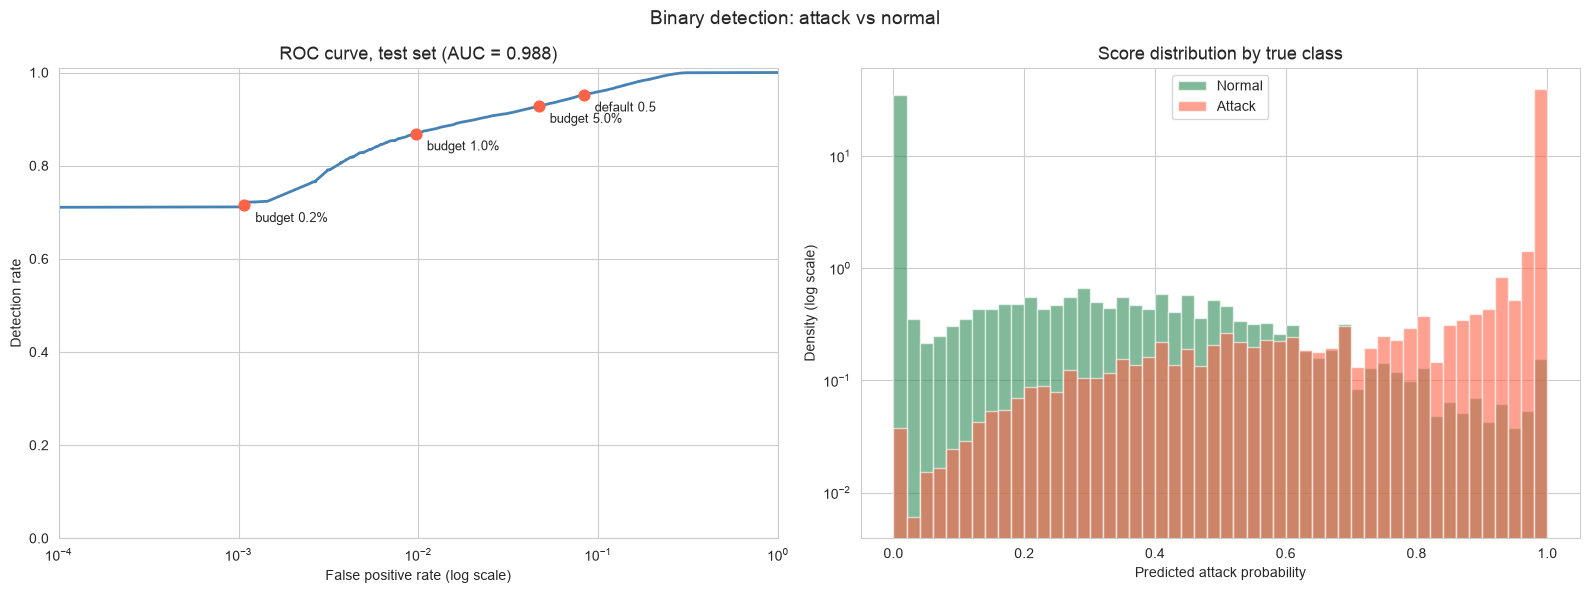

In [6]:
fpr_test, tpr_test, _ = roc_curve(ybin_test, p_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(fpr_test, tpr_test, color='steelblue', lw=2)
axes[0].set_xscale('log')
axes[0].set_xlim(1e-4, 1)
axes[0].set_ylim(0, 1.01)
axes[0].set_xlabel('False positive rate (log scale)')
axes[0].set_ylabel('Detection rate')
axes[0].set_title(f'ROC curve, test set (AUC = {roc_auc_score(ybin_test, p_test):.3f})')
for _, r in thresholds.iterrows():
    axes[0].scatter(r['False positive rate'], r['Detection rate'], s=60, zorder=3, color='tomato')
    label = 'default 0.5' if pd.isna(r['Target FPR (validation)']) else f"budget {r['Target FPR (validation)']:.1%}"
    axes[0].annotate(label, (r['False positive rate'], r['Detection rate']),
                     textcoords='offset points', xytext=(8, -12), fontsize=9)

axes[1].hist(p_test[ybin_test == 0], bins=50, alpha=0.6, label='Normal', color='seagreen', density=True)
axes[1].hist(p_test[ybin_test == 1], bins=50, alpha=0.6, label='Attack', color='tomato', density=True)
axes[1].set_yscale('log')
axes[1].set_xlabel('Predicted attack probability')
axes[1].set_ylabel('Density (log scale)')
axes[1].set_title('Score distribution by true class')
axes[1].legend()

plt.suptitle('Binary detection: attack vs normal', fontsize=14)
plt.tight_layout()
save('soc_roc_threshold')
plt.show()

## 3. What a false positive rate means in practice

Rates hide scale. The table below translates each threshold into **false alarms per day** for a network
that sees a given number of benign flows per day. The volumes are illustrative: a small office can produce
around 100,000 flows a day, and a mid-sized organization millions.

In [7]:
volumes = [100_000, 1_000_000, 10_000_000]
alert_rows = []
for _, r in thresholds.iterrows():
    label = 'Default (0.5)' if pd.isna(r['Target FPR (validation)']) else f"Budget {r['Target FPR (validation)']:.1%}"
    row = {'Threshold setting': label,
           'Detection rate': r['Detection rate'],
           'FPR': r['False positive rate']}
    for v in volumes:
        row[f'False alarms/day @ {v:,} benign flows'] = int(round(r['False positive rate'] * v))
    alert_rows.append(row)

pd.DataFrame(alert_rows).round(4)

,Threshold setting,Detection rate,FPR,"False alarms/day @ 100,000 benign flows","False alarms/day @ 1,000,000 benign flows","False alarms/day @ 10,000,000 benign flows"
0,Default (0.5),0.9520,0.0830,8301,83011,830108
1,Budget 5.0%,0.9277,0.0467,4667,46667,466667
2,Budget 1.0%,0.8686,0.0097,968,9677,96774
3,Budget 0.2%,0.7147,0.0011,108,1075,10753


## 4. Which attack types slip through?

The overall detection rate hides big differences between attack categories. Below is the share of each
attack type that raises an alert at each threshold.

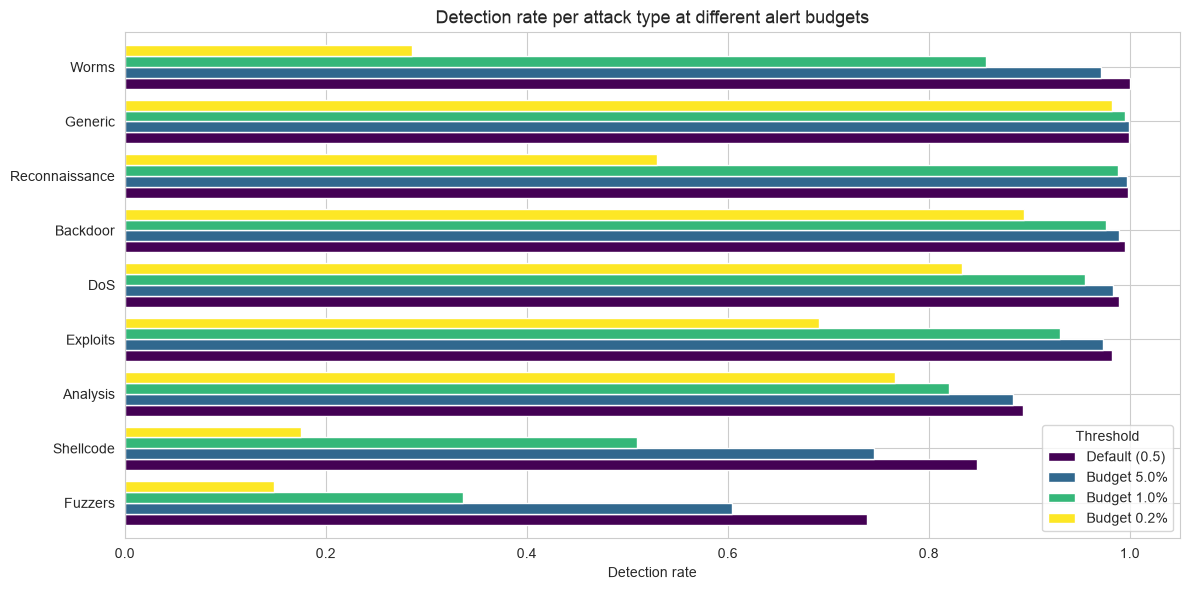

,Default (0.5),Budget 5.0%,Budget 1.0%,Budget 0.2%,Test samples
Analysis,0.893,0.884,0.821,0.766,535
Backdoor,0.996,0.989,0.976,0.895,466
DoS,0.989,0.983,0.955,0.833,3271
Exploits,0.982,0.973,0.931,0.691,8905
Fuzzers,0.738,0.604,0.337,0.148,4849
Generic,0.999,0.999,0.995,0.983,11774
Reconnaissance,0.999,0.997,0.988,0.530,2798
Shellcode,0.848,0.745,0.510,0.175,302
Worms,1.000,0.971,0.857,0.286,35


In [8]:
attack_types = sorted(c for c in ycat_test.unique() if c != 'Normal')
per_type = {}
for _, r in thresholds.iterrows():
    label = 'Default (0.5)' if pd.isna(r['Target FPR (validation)']) else f"Budget {r['Target FPR (validation)']:.1%}"
    flagged = p_test >= r['Threshold']
    per_type[label] = {c: flagged[(ycat_test == c).to_numpy()].mean() for c in attack_types}

per_type = pd.DataFrame(per_type)
per_type['Test samples'] = [int((ycat_test == c).sum()) for c in attack_types]

plt.figure(figsize=(12, 6))
plot_df = per_type.drop(columns='Test samples').sort_values('Default (0.5)')
plot_df.plot(kind='barh', ax=plt.gca(), width=0.8, colormap='viridis')
plt.xlabel('Detection rate')
plt.xlim(0, 1.05)
plt.title('Detection rate per attack type at different alert budgets')
plt.legend(title='Threshold', loc='lower right')
plt.tight_layout()
save('soc_detection_per_type')
plt.show()

per_type.round(3)

### What this means for a SOC

**Detecting *that* something is an attack is much easier than saying *which* attack it is.** The binary model
reaches a ROC AUC of 0.988 and flags 95% of attacks at the default threshold. The three classes that were hardest
in the ten-class setting (Backdoor, DoS and Analysis, all with F1 below 0.25 in notebook 01) are flagged as
attacks 89-99% of the time. The model recognizes them as malicious but cannot tell them apart from `Exploits`.
A practical design is therefore two-stage: a binary detector decides whether to alert, and the attack category is
shown to the analyst as a triage hint, not as a verdict.

**The default threshold is unusable in practice.** An 8.3% false positive rate means more than 80,000 false
alarms per day on a network with one million benign flows. No team can triage that.

| Alert budget | Detection rate | False alarms/day @ 1M benign flows |
|---|---|---|
| Default (0.5) | 95.2% | ~83,000 |
| 5% | 92.8% | ~47,000 |
| 1% | 86.9% | ~9,700 |
| 0.2% | 71.5% | ~1,100 |

Even at the strictest budget, per-flow alerting produces about a thousand alerts a day. In a real deployment
the flows would have to be **aggregated** (per host, session or time window) and combined with other signals
before they become alerts.

**There is a hard floor on false positives.** 0.19% of benign validation flows get an attack probability of
exactly 1.0. They are identical to attack flows on every feature (see the label-overlap analysis in notebook 02),
so no threshold can remove them.

**Strict budgets hide specific attack types.** At the 0.2% budget, Generic, Backdoor and DoS are still detected
83-98% of the time, but only 15% of Fuzzers, 18% of Shellcode and 29% of Worms raise an alert. Fuzzers look
like normal traffic (30% of them were classified as Normal in notebook 01), and Shellcode and Worms are rare
enough that the model is rarely confident about them. Choosing a threshold is therefore not only a question of
analyst capacity, but also of **which attack types the organization can accept missing**.

## 5. Limitation: duplicate records and an honest re-split

Notebook 02 showed that the 257,673 rows contain only ~139,000 distinct feature vectors. With a random split,
an identical copy of many test rows is already in the training set, so part of the test score measures
**memorization rather than generalization**.

To estimate how large this effect is, the data is:

1. **de-duplicated**: exact duplicates (same features *and* same label) are kept only once, and
2. **split by feature vector**: `StratifiedGroupKFold` puts every copy of a feature vector (including copies with
   different labels) on the same side of the split, while keeping the class proportions.

The same models are then trained on both setups and compared.

In [9]:
feature_cols = [c for c in df.columns if c not in ('id', 'label', TARGET)]

df_dedup = df.drop_duplicates(subset=feature_cols + [TARGET]).reset_index(drop=True)
groups = pd.util.hash_pandas_object(df_dedup[feature_cols], index=False).to_numpy()

print(f'Rows before de-duplication: {len(df):,}')
print(f'Rows after  de-duplication: {len(df_dedup):,} ({len(df_dedup) / len(df):.1%} kept)')
print()
print('Rows kept per class:')
print((df_dedup[TARGET].value_counts() / df[TARGET].value_counts()).round(3).sort_values()
      .rename('share kept').to_frame().join(df_dedup[TARGET].value_counts().rename('rows')))

Rows before de-duplication: 257,673
Rows after  de-duplication: 145,222 (56.4% kept)

Rows kept per class:
                share kept   rows
attack_cat                       
Generic              0.052   3057
DoS                  0.298   4873
Analysis             0.539   1442
Reconnaissance       0.573   8012
Backdoor             0.596   1389
Exploits             0.601  26749
Fuzzers              0.755  18313
Shellcode            0.832   1257
Normal               0.860  79965
Worms                0.948    165


In [10]:
Xd_encoded, yd_cat = encode_features(df_dedup)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, te_idx = next(sgkf.split(Xd_encoded, yd_cat, groups))

shared = np.intersect1d(groups[tr_idx], groups[te_idx]).size
print(f'Train: {len(tr_idx):,} | Test: {len(te_idx):,} | feature vectors in both sets: {shared}')

scaler_d = StandardScaler()
Xd_train = scaler_d.fit_transform(Xd_encoded.iloc[tr_idx]).astype(np.float32)
Xd_test = scaler_d.transform(Xd_encoded.iloc[te_idx]).astype(np.float32)
yd_train, yd_test = yd_cat.iloc[tr_idx].to_numpy(), yd_cat.iloc[te_idx].to_numpy()

Train: 116,177 | Test: 29,045 | feature vectors in both sets: 0


In [11]:
def evaluate(setup, Xtr, Xte, ytr_cat, yte_cat):
    rows = []
    mc = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr_cat)
    pred = mc.predict(Xte)
    rows.append({'Setup': setup, 'Task': 'Multi-class (RF balanced)',
                 'Accuracy': accuracy_score(yte_cat, pred),
                 'Macro F1': f1_score(yte_cat, pred, average='macro', zero_division=0),
                 'ROC AUC': np.nan, 'Detection rate': np.nan, 'FPR': np.nan})

    ytr_b, yte_b = (ytr_cat != 'Normal').astype(int), (yte_cat != 'Normal').astype(int)
    bn = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr_b)
    scores = bn.predict_proba(Xte)[:, 1]
    s = detection_stats(yte_b, scores, 0.5)
    rows.append({'Setup': setup, 'Task': 'Binary (RF, threshold 0.5)',
                 'Accuracy': accuracy_score(yte_b, scores >= 0.5),
                 'Macro F1': f1_score(yte_b, scores >= 0.5, average='macro'),
                 'ROC AUC': roc_auc_score(yte_b, scores),
                 'Detection rate': s['Detection rate'], 'FPR': s['False positive rate']})
    return rows, pred

orig_rows, _ = evaluate('Random split (notebooks 01-02)', X_train_s, X_test_s,
                        ycat_train.to_numpy(), ycat_test.to_numpy())
dedup_rows, dedup_pred = evaluate('De-duplicated, group split', Xd_train, Xd_test, yd_train, yd_test)

comparison = pd.DataFrame(orig_rows + dedup_rows).sort_values(['Task', 'Setup']).reset_index(drop=True)
comparison.round(4)

,Setup,Task,Accuracy,Macro F1,ROC AUC,Detection rate,FPR
0,"De-duplicated, group split","Binary (RF, threshold 0.5)",0.9041,0.9030,0.9747,0.8861,0.0811
1,Random split (notebooks 01-02),"Binary (RF, threshold 0.5)",0.9401,0.9351,0.9885,0.9515,0.0803
2,"De-duplicated, group split",Multi-class (RF balanced),0.7766,0.5870,NaN,NaN,NaN
3,Random split (notebooks 01-02),Multi-class (RF balanced),0.7554,0.5455,NaN,NaN,NaN


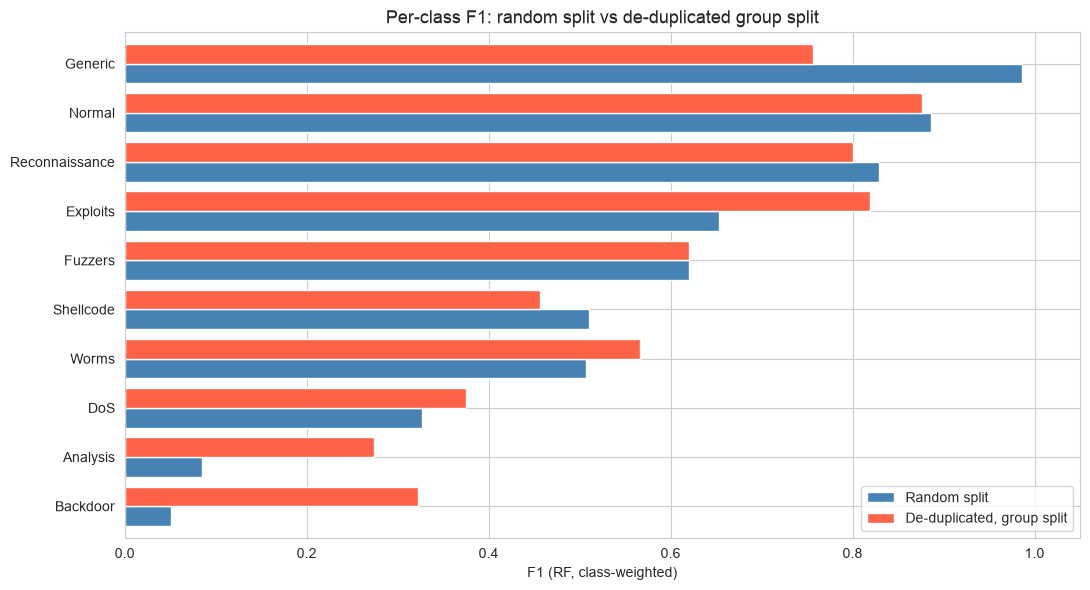

,Random split,"De-duplicated, group split",Change
Generic,0.986,0.757,-0.230
Shellcode,0.511,0.457,-0.054
Reconnaissance,0.830,0.801,-0.029
Normal,0.887,0.877,-0.010
Fuzzers,0.621,0.620,-0.000
DoS,0.327,0.375,0.049
Worms,0.507,0.567,0.060
Exploits,0.653,0.820,0.167
Analysis,0.085,0.274,0.190
Backdoor,0.050,0.323,0.272


In [12]:
def per_class_f1(y_true, y_pred):
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return pd.Series({c: rep[c]['f1-score'] for c in sorted(np.unique(y_true))})


rf_orig = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_s, ycat_train)
f1_cmp = pd.DataFrame({
    'Random split': per_class_f1(ycat_test, rf_orig.predict(X_test_s)),
    'De-duplicated, group split': per_class_f1(yd_test, dedup_pred),
})
f1_cmp['Change'] = f1_cmp['De-duplicated, group split'] - f1_cmp['Random split']

f1_cmp.drop(columns='Change').sort_values('Random split').plot(kind='barh', figsize=(11, 6), width=0.8,
                                                               color=['steelblue', 'tomato'])
plt.xlabel('F1 (RF, class-weighted)')
plt.xlim(0, 1.05)
plt.title('Per-class F1: random split vs de-duplicated group split')
plt.tight_layout()
save('dedup_per_class_f1')
plt.show()

f1_cmp.round(3).sort_values('Change')

### Results of the re-split

Only **56% of the rows are unique**. For `Generic` just 5% of the rows are unique, and for `DoS` 30%.

| Task | Metric | Random split | De-duplicated, group split |
|---|---|---|---|
| Binary | Detection rate | 0.952 | 0.886 |
| Binary | ROC AUC | 0.989 | 0.975 |
| Binary | False positive rate | 0.080 | 0.081 |
| Multi-class | Macro F1 | 0.546 | 0.587 |

- **Binary detection was inflated.** When the model can no longer meet the same flows in training and testing,
  the detection rate drops by about 6.5 percentage points at the same false positive rate. Part of the earlier
  score was memorization of repeated flows.
- **Per-class scores shift in both directions.** `Generic` drops from 0.99 to 0.76 F1: its near-perfect score
  came mostly from recognizing repeated flows. `Backdoor`, `Analysis` and `Exploits`, on the other hand, *improve*
  (0.05 to 0.32 F1 for Backdoor), because the large blocks of duplicated rows that made them indistinguishable
  are reduced to one copy each.
- **Macro F1 is not directly comparable** between the two setups, since the test set has a different class
  composition. The higher multi-class score does not mean the model got better.
- The comparison of imbalance techniques in notebook 01 was not repeated on the de-duplicated split, so its
  ranking should be read with this caveat in mind.

**Takeaway:** the headline numbers in notebooks 01-02 are somewhat optimistic, most of all for `Generic` and for
binary detection. Any production evaluation should de-duplicate and use a group-aware (or time-based) split.

## 6. Other limitations

- **Synthetic, dated traffic.** UNSW-NB15 was generated in a lab testbed in 2015. Attack tools, protocols and
  normal traffic patterns have changed since then. In particular, much more traffic is encrypted today.
- **Random rather than time-based split.** Real detectors are trained on the past and used on the future. A random
  split ignores concept drift, so real-world performance would likely be lower.
- **Flow-level features only.** There is no payload or host context, which limits how well similar attack
  categories can be separated (as the label-overlap analysis shows).
- **Label quality.** Identical flows with different labels point to labelling noise or to categories that cannot
  be separated at flow level.
- **One dataset.** The models were not validated on a second dataset (for example CIC-IDS2017), so it is unknown
  how well they transfer to other networks.
- **Per-flow evaluation.** A SOC works with incidents, not individual flows. One missed flow does not necessarily
  mean a missed attack, and one noisy host can produce thousands of false alarms.